In [76]:
import pandas as pd

In [77]:
import pandas as pd
df = pd.read_csv("OnlineRetail.csv", encoding="latin1")
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [39]:
df.shape

(541909, 8)

In [40]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [41]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [43]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [44]:
df.select_dtypes(include='number').mean()

Quantity          9.552250
UnitPrice         4.611114
CustomerID    15287.690570
dtype: float64

In [45]:
df.select_dtypes(include='number').median()

Quantity          3.00
UnitPrice         2.08
CustomerID    15152.00
dtype: float64

In [46]:
df.select_dtypes(include='number').mode()

,Quantity,UnitPrice,CustomerID
0,1,1.25,17841.0


In [47]:
df.select_dtypes(include='number').std()

Quantity       218.081158
UnitPrice       96.759853
CustomerID    1713.600303
dtype: float64

In [82]:
import matplotlib.pyplot as plt

In [83]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate']) 

In [84]:
monthly_sales = df.resample('ME', on='InvoiceDate')['Quantity'].sum()


In [85]:
monthly_sales=df.resample('ME',on='InvoiceDate')['Quantity'].sum()

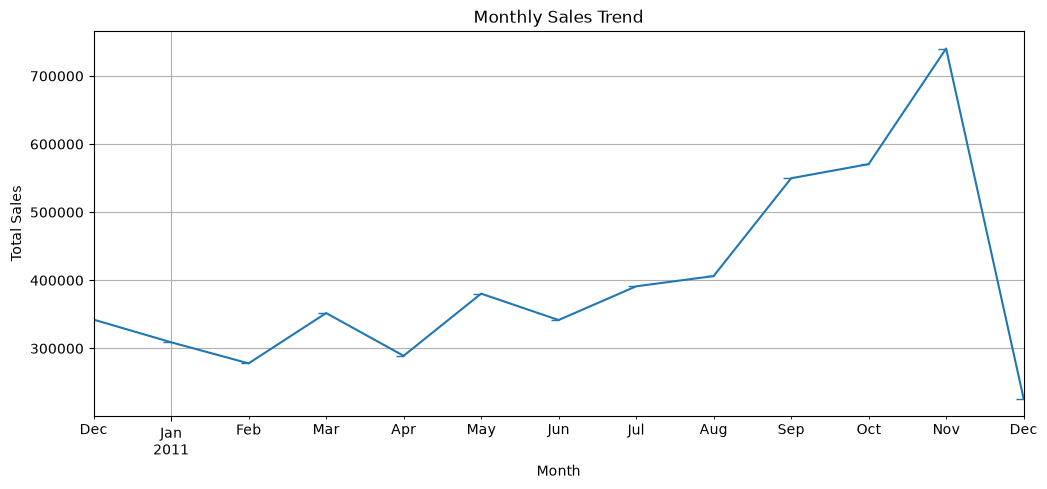

In [86]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
monthly_sales.plot(kind="line",marker=0)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid("True")
plt.show()

In [87]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [88]:
import matplotlib.pyplot as plt

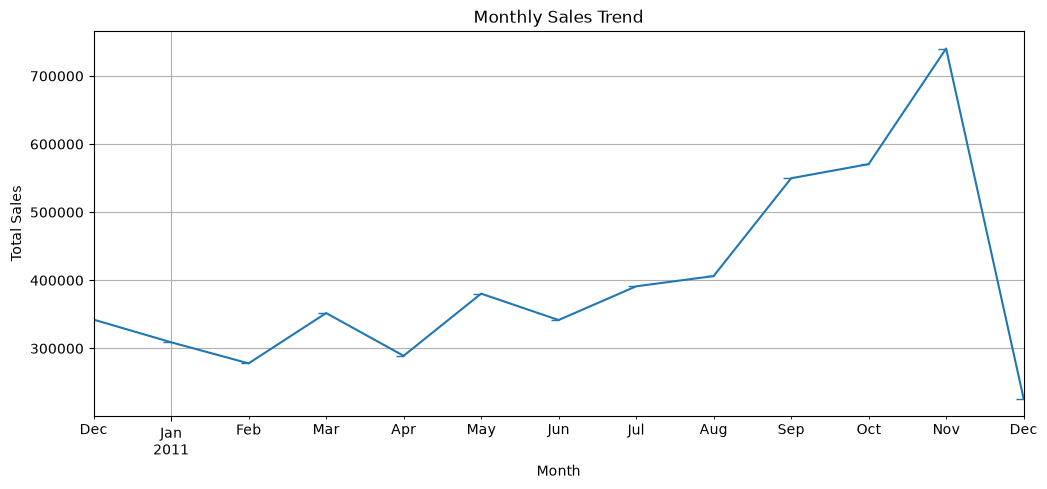

In [89]:
plt.figure(figsize=(12,5))
monthly_sales.plot(kind="line",marker=0)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid("True")
plt.show()

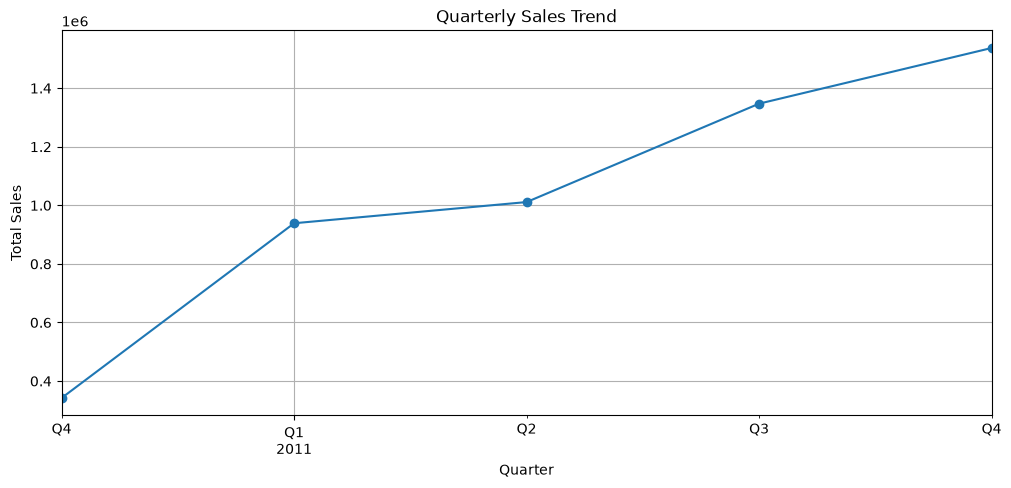

In [90]:
quarterly_sales=df.resample('QE',on='InvoiceDate')['Quantity'].sum()
plt.figure(figsize=(12,5))

quarterly_sales.plot(kind="line", marker="o")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)

plt.show()

In [91]:
country_customers = df.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False)

print(country_customers.head(10))

Country
United Kingdom    3950
Germany             95
France              87
Spain               31
Belgium             25
Switzerland         21
Portugal            19
Italy               15
Finland             12
Austria             11
Name: CustomerID, dtype: int64


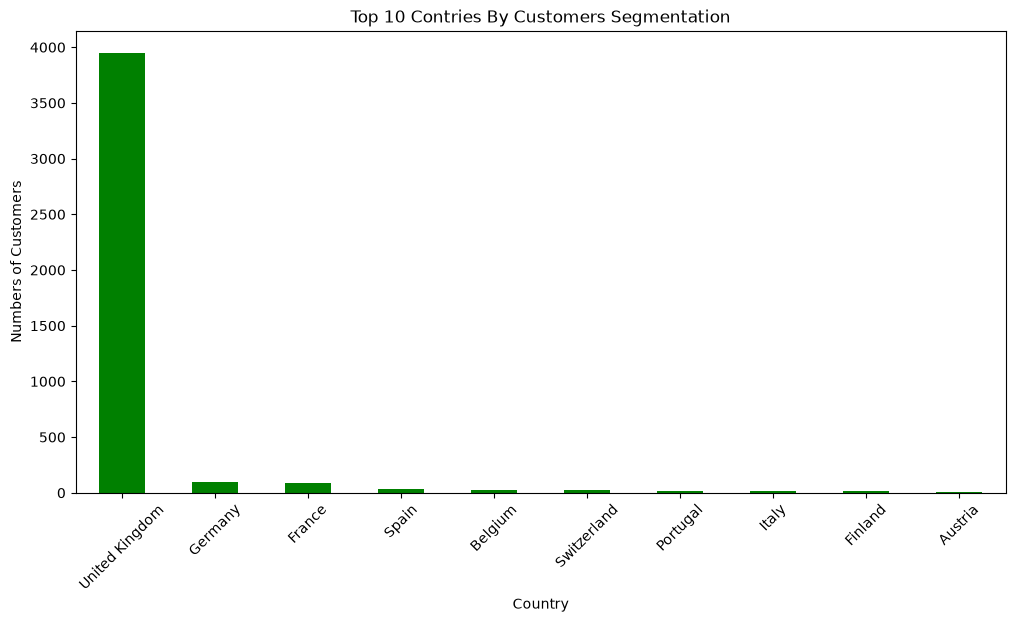

In [92]:
plt.figure(figsize=(12,6))
country_customers.head(10).plot(kind="bar",color="green")
plt.title("Top 10 Contries By Customers Segmentation")
plt.xlabel("Country")
plt.ylabel("Numbers of Customers")
plt.xticks(rotation=45)
plt.show()

In [93]:
total_customers = df['CustomerID'].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 4372


In [94]:
customer_purchases = df.groupby('CustomerID')['InvoiceNo'].nunique()

print(customer_purchases.describe())

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64


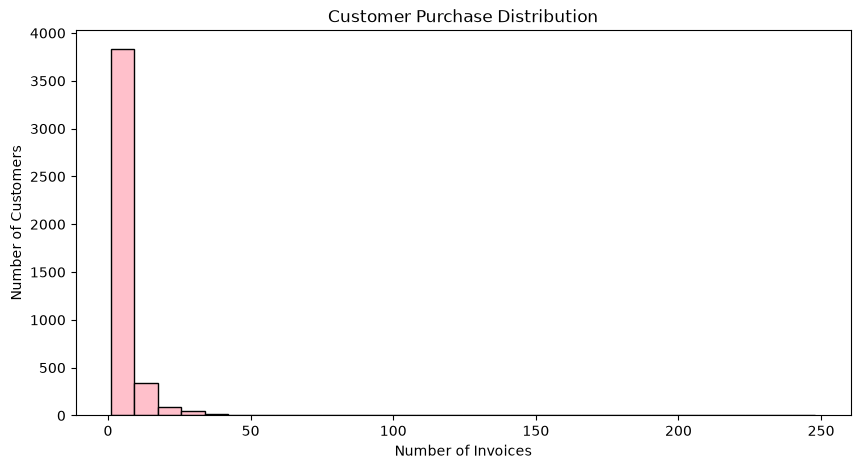

In [95]:
plt.figure(figsize=(10,5))

customer_purchases.plot(kind='hist', bins=30, edgecolor='black',color='pink')

plt.title('Customer Purchase Distribution')
plt.xlabel('Number of Invoices')
plt.ylabel('Number of Customers')

plt.show()

In [96]:
%pip install seaborn 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [97]:
import seaborn as sns

In [98]:
df['Sales']=df['Quantity']*df['UnitPrice']

In [99]:
numerical_df=df[['Quantity','UnitPrice','Sales']]

In [100]:
correlation_matrix=numerical_df.corr()
print("correlation_matrix")

correlation_matrix


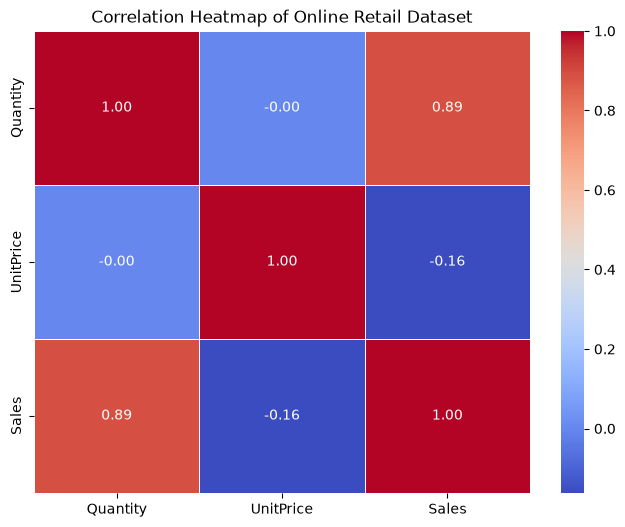

In [101]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of Online Retail Dataset')
plt.show()

In [102]:
df['Sales']=df['Quantity']*df['UnitPrice']

In [103]:
product_sales=df.groupby('Description')['Sales'].sum()

In [104]:
top_products=product_sales.sort_values(ascending=False).head(10)

In [105]:
print(top_products)

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164762.19
WHITE HANGING HEART T-LIGHT HOLDER     99668.47
PARTY BUNTING                          98302.98
JUMBO BAG RED RETROSPOT                92356.03
RABBIT NIGHT LIGHT                     66756.59
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63791.94
ASSORTED COLOUR BIRD ORNAMENT          58959.73
CHILLI LIGHTS                          53768.06
Name: Sales, dtype: float64


ValueError: keyword grid_linstyle is not recognized; valid keywords are ['size', 'width', 'color', 'tickdir', 'pad', 'labelsize', 'labelcolor', 'labelfontfamily', 'zorder', 'gridOn', 'tick1On', 'tick2On', 'label1On', 'label2On', 'length', 'direction', 'left', 'bottom', 'right', 'top', 'labelleft', 'labelbottom', 'labelright', 'labeltop', 'labelrotation', 'labelrotation_mode', 'grid_agg_filter', 'grid_alpha', 'grid_animated', 'grid_antialiased', 'grid_clip_box', 'grid_clip_on', 'grid_clip_path', 'grid_color', 'grid_dash_capstyle', 'grid_dash_joinstyle', 'grid_dashes', 'grid_data', 'grid_drawstyle', 'grid_figure', 'grid_fillstyle', 'grid_gapcolor', 'grid_gid', 'grid_in_layout', 'grid_label', 'grid_linestyle', 'grid_linewidth', 'grid_marker', 'grid_markeredgecolor', 'grid_markeredgewidth', 'grid_markerfacecolor', 'grid_markerfacecoloralt', 'grid_markersize', 'grid_markevery', 'grid_mouseover', 'grid_path_effects', 'grid_picker', 'grid_pickradius', 'grid_rasterized', 'grid_sketch_params', 

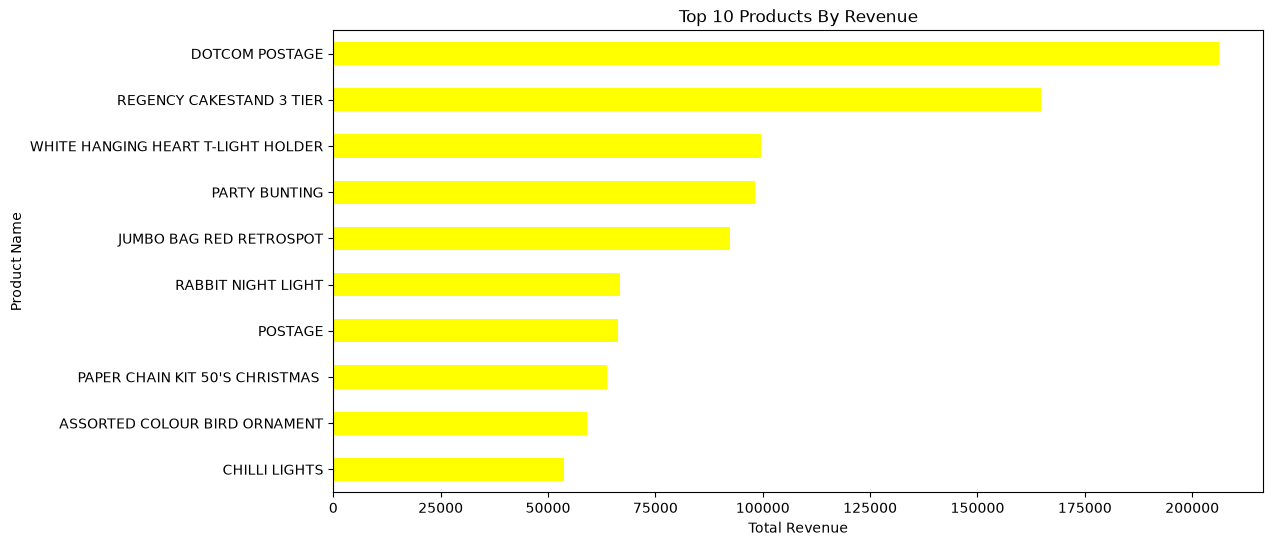

In [106]:
plt.figure(figsize=(12,6))
top_products.sort_values().plot(kind="barh",color="Yellow")
plt.title("Top 10 Products By Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")
plt.grid(axis='x',linstyle='--',alpha=0.5)
plt.show()

In [107]:
total_revenue = df['Sales'].sum()

revenue_percentage = (top_products / total_revenue) * 100

print("Revenue Contribution (%):")
print(revenue_percentage.round(2))

Revenue Contribution (%):
Description
DOTCOM POSTAGE                        2.12
REGENCY CAKESTAND 3 TIER              1.69
WHITE HANGING HEART T-LIGHT HOLDER    1.02
PARTY BUNTING                         1.01
JUMBO BAG RED RETROSPOT               0.95
RABBIT NIGHT LIGHT                    0.68
POSTAGE                               0.68
PAPER CHAIN KIT 50'S CHRISTMAS        0.65
ASSORTED COLOUR BIRD ORNAMENT         0.60
CHILLI LIGHTS                         0.55
Name: Sales, dtype: float64
